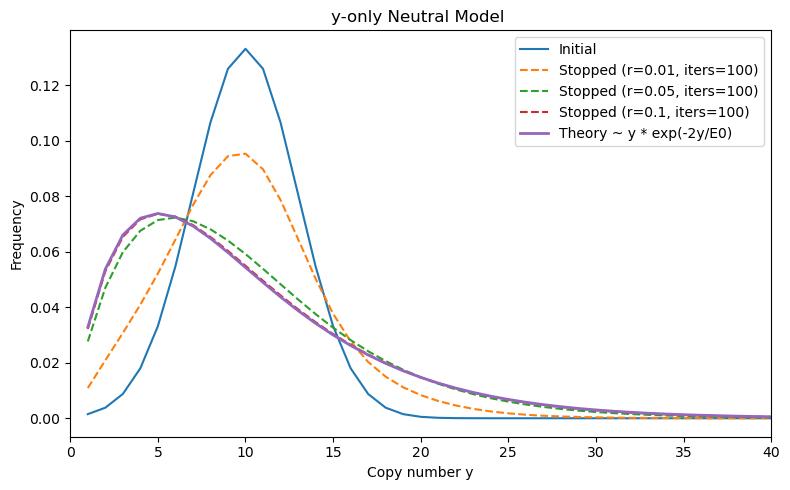

In [53]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# distributions & math
# -----------------------------

def trapez_tensor(n: int) -> np.ndarray: #3D-tensor
    """
    Compute trapezoid distribution tensor T[k,y1,y2].
    Each slice T[:, y1, y2] gives P(k | y1,y2).
    """
    K  = np.arange(1, n + 1)[:, None, None]  # shape (n,1,1)
    Y1 = np.arange(1, n + 1)[None, :, None]  # (1,n,1)
    Y2 = np.arange(1, n + 1)[None, None, :]  # (1,1,n)

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)

    # valid range
    valid = (K <= (ysum - 1))

    # main value using vectorized where
    val = np.where(K <= ymin, K,                # case A
          np.where(K <= ymax, ymin,             # case B
          np.where(valid, ysum - K, 0.0)))      # case C and invalid

    # normalize by y1*y2, zero out invalid
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T



def f_post_neutral(f_prior: np.ndarray, r: float, T: np.ndarray) -> np.ndarray:
    """
    One-generation update under neutrality.

    f_post(k) = (1 - r) * f_prior(k) + r * sum_{y1,y2} f(y1) f(y2) T[k, y1, y2]

    - Exploits the identity that the no-recombination part collapses to (1-r) * f.
    - Recombinant part is an einsum over the precomputed kernel T.

    Inputs:
      f_prior: shape (n,), probabilities over y=1..n
      r: recombination probability
      T: shape (n,n,n) = trapez_tensor(n)
    """
    f_prior = f_prior.astype(float)
    f_prior /= f_prior.sum()

    # recombinant mixture: r * sum_{y1,y2} f(y1) f(y2) T[k,y1,y2]
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)

    f_post = (1.0 - r) * f_prior + r * recomb
    # renormalize (in case you truncate the support to 1..n)
    f_post /= f_post.sum()
    return f_post


def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    """
    The neutral pseudo-equilibrium (given initial mean E0):
      P(y) ∝ y * exp(-2y / E0), for y = 1..n
    """
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    p /= p.sum()
    return p


def iterate_until_convergence(f0: np.ndarray, r: float, T: np.ndarray,
                              tol: float = 1e-8, max_iter: int = 10000):
    """
    Iterate f_post under neutrality until L1 difference < tol or max_iter hit.
    Returns (f, iters, converged: bool).
    """
    f = f0 / f0.sum()
    for it in range(1, max_iter + 1):
        f_new = f_post_neutral(f, r, T)
        diff = np.abs(f_new - f).sum()
        f = f_new
        if diff < tol:
            return f, it, True
    return f, max_iter, False


# -----------------------------
# Demo usage
# -----------------------------
if __name__ == "__main__":
    # Model size and recombination
    n = 100
    r_list = [0.01, 0.05, 0.1]

    # Precompute trapezoid kernel once
    T = trapez_tensor(n)

    # Initial distribution: a Gaussian-shaped prior around 10
    y = np.arange(1, n + 1)
    f0 = np.exp(-((y - 10.0) ** 2) / (2.0 * 3.0 ** 2))
    f0 /= f0.sum()

    # Theoretical neutral "stationary" given initial mean
    E0 = (y * f0).sum()
    f_theory = stationary_theory_from_mean(E0, n)

    plt.figure(figsize=(8, 5))
    plt.plot(y, f0, label="Initial", linewidth=1.5)

    # Show how r affects only the speed, not the equilibrium shape
    for r in r_list:
        f_conv, iters, ok = iterate_until_convergence(f0, r, T, tol=1e-10, max_iter=100)
        lbl = f"Converged (r={r}, iters={iters})" if ok else f"Stopped (r={r}, iters={iters})"
        plt.plot(y, f_conv, label=lbl, linestyle="--")

    # Plot theory (overlaps with the high-iteration curves)
    plt.plot(y, f_theory, label="Theory ~ y * exp(-2y/E0)", linewidth=2)

    plt.xlabel("Copy number y")
    plt.ylabel("Frequency")
    plt.title("y-only Neutral Model ")
    plt.legend()
    plt.xlim(0, 40)
    plt.tight_layout()
    plt.show()


mean copy number E0 = 10.002603591030297


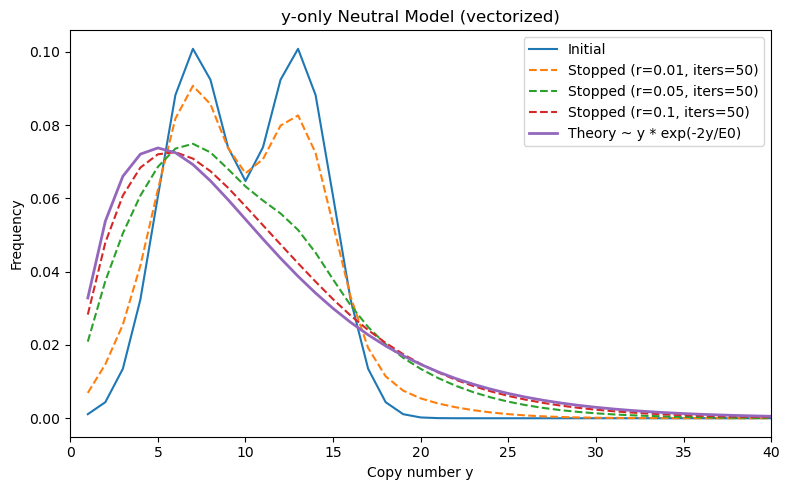

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# distributions & math
# -----------------------------

def trapez_tensor(n: int) -> np.ndarray:
    """
    Compute trapezoid distribution tensor T[k,y1,y2].
    Each slice T[:, y1, y2] gives P(k | y1,y2).
    """
    K  = np.arange(1, n + 1)[:, None, None]  # shape (n,1,1)
    Y1 = np.arange(1, n + 1)[None, :, None]  # (1,n,1)
    Y2 = np.arange(1, n + 1)[None, None, :]  # (1,1,n)

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)

    # valid range
    valid = (K <= (ysum - 1))

    # main value using vectorized where
    val = np.where(K <= ymin, K,                # case A
          np.where(K <= ymax, ymin,             # case B
          np.where(valid, ysum - K, 0.0)))      # case C and invalid

    # normalize by y1*y2, zero out invalid
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T



def f_post_neutral(f_prior: np.ndarray, r: float, T: np.ndarray) -> np.ndarray:
    """
    One-generation update under neutrality.

    f_post(k) = (1 - r) * f_prior(k) + r * sum_{y1,y2} f(y1) f(y2) T[k, y1, y2]

    - Exploits the identity that the no-recombination part collapses to (1-r) * f.
    - Recombinant part is an einsum over the precomputed kernel T.

    Inputs:
      f_prior: shape (n,), probabilities over y=1..n
      r: recombination probability
      T: shape (n,n,n) = trapez_tensor(n)
    """
    f_prior = f_prior.astype(float)
    f_prior /= f_prior.sum()

    # recombinant mixture: r * sum_{y1,y2} f(y1) f(y2) T[k,y1,y2]
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)

    f_post = (1.0 - r) * f_prior + r * recomb
    # renormalize (in case you truncate the support to 1..n)
    f_post /= f_post.sum()
    return f_post


def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    """
    The neutral pseudo-equilibrium (given initial mean E0):
      P(y) ∝ y * exp(-2y / E0), for y = 1..n
    """
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    p /= p.sum()
    return p


def iterate_until_convergence(f0: np.ndarray, r: float, T: np.ndarray,
                              tol: float = 1e-8, max_iter: int = 10000):
    """
    Iterate f_post under neutrality until L1 difference < tol or max_iter hit.
    Returns (f, iters, converged: bool).
    """
    f = f0 / f0.sum()
    for it in range(1, max_iter + 1):
        f_new = f_post_neutral(f, r, T)
        diff = np.abs(f_new - f).sum()
        f = f_new
        if diff < tol:
            return f, it, True
    return f, max_iter, False


# -----------------------------
# Demo usage
# -----------------------------
if __name__ == "__main__":
    # Model size and recombination
    n = 100
    r_list = [0.01, 0.05, 0.1]

    # Precompute trapezoid kernel once
    T = trapez_tensor(n)

    # Two Gaussian peaks around mean = 10
    y = np.arange(1, n + 1)

    peak1_center = 7
    peak2_center = 13
    sd = 2.0

    f0 = 0.5 * np.exp(-((y - peak1_center) ** 2) / (2 * sd**2)) \
         + 0.5 * np.exp(-((y - peak2_center) ** 2) / (2 * sd**2))

    f0 /= f0.sum()

    E0 = np.sum(y * f0)
    print("mean copy number E0 =", E0)
    # Theoretical neutral "stationary" given initial mean
    E0 = (y * f0).sum()
    f_theory = stationary_theory_from_mean(E0, n)

    plt.figure(figsize=(8, 5))
    plt.plot(y, f0, label="Initial", linewidth=1.5)

    # Show how r affects only the speed, not the equilibrium shape
    for r in r_list:
        f_conv, iters, ok = iterate_until_convergence(f0, r, T, tol=1e-10, max_iter=50)
        lbl = f"Converged (r={r}, iters={iters})" if ok else f"Stopped (r={r}, iters={iters})"
        plt.plot(y, f_conv, label=lbl, linestyle="--")

    # Plot theory (overlaps with the high-iteration curves)
    plt.plot(y, f_theory, label="Theory ~ y * exp(-2y/E0)", linewidth=2)

    plt.xlabel("Copy number y")
    plt.ylabel("Frequency")
    plt.title("y-only Neutral Model (vectorized)")
    plt.legend()
    plt.xlim(0, 40)
    plt.tight_layout()
    plt.show()

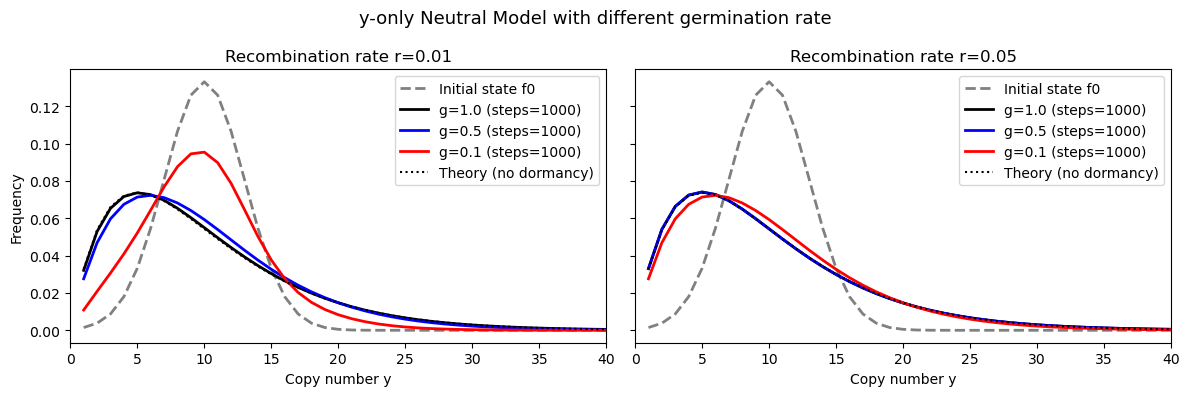

In [29]:


# ---------- trapez kernel ----------
def trapez_tensor(n: int) -> np.ndarray:
    K  = np.arange(1, n + 1)[:, None, None]
    Y1 = np.arange(1, n + 1)[None, :, None]
    Y2 = np.arange(1, n + 1)[None, None, :]

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T

# ---------- dormancy/germination update ----------
def f_post_neutral_germination(f_prior, r, g, T):
    """Deterministic neutral model with germination rate g."""
    f_prior = f_prior / f_prior.sum()
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)
    f_new = (1 - r) * f_prior + r * recomb
    f_post = g * f_new + (1 - g) * f_prior
    return f_post / f_post.sum()

def iterate_germination(f0, r, g, T, tol=1e-9, max_iter=1000):
    f = f0 / f0.sum()
    for i in range(max_iter):
        f_new = f_post_neutral_germination(f, r, g, T)
        if np.abs(f_new - f).sum() < tol:
            return f_new, i
        f = f_new
    return f, max_iter

# ---------- theoretical neutral stationary (only for g=1) ----------
def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    return p / p.sum()

# ---------- run simulation ----------
if __name__ == "__main__":
    n = 80  # maximum copy number considered
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # initial distribution: gaussian around y=10
    f0 = np.exp(-((y - 10.0) ** 2) / (2 * 3.0 ** 2))
    f0 /= f0.sum()
    E0 = np.sum(y * f0)
    theory = stationary_theory_from_mean(E0, n)
    
    # Initial distribution: bimodal
    #f0 = np.zeros(n)
    #f0[5] = 0.4     # peak at y=6
    #f0[20] = 0.4    # peak at y=31
    #E0 = np.sum(y * f0)
    #theory = stationary_theory_from_mean(E0, n)

    recomb_rates = [0.01, 0.05]
    germ_rates = [1.0, 0.5, 0.1]   # 1=no dormancy, 0.5=avg 2-gen dormancy, 0.1=strong dormancy
    colors = ["black", "blue", "red"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, r in zip(axes, recomb_rates):
        # plot initial distribution
        ax.plot(y, f0, "gray", linestyle="--", lw=2, label="Initial state f0")
        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_germination(f0, r, g, T)
            ax.plot(y, f_eq, color=col, lw=2,
                    label=f"g={g} (steps={steps})")
        # only show theory for g=1
        ax.plot(y, theory, "k:", lw=1.5, label="Theory (no dormancy)")
        ax.set_title(f"Recombination rate r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 40)
        ax.legend()
    axes[0].set_ylabel("Frequency")
    fig.suptitle("y-only Neutral Model with different germination rate", fontsize=13)
    plt.tight_layout()
    plt.show()

   

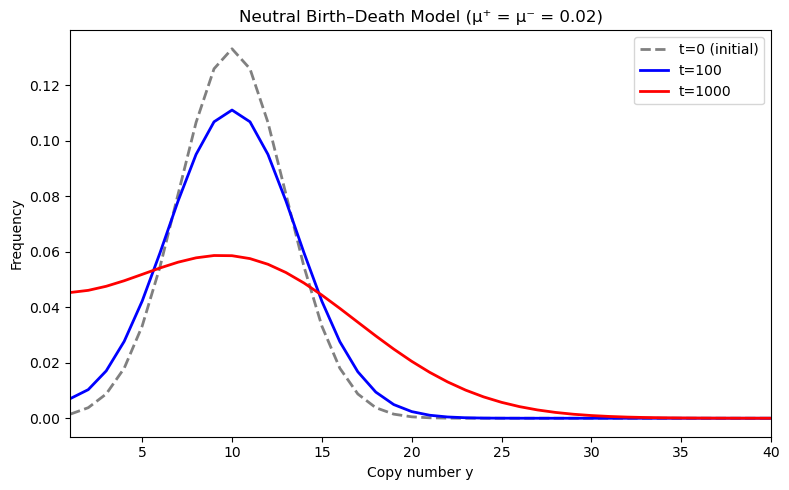

In [30]:


def bd_step(f, mu_plus, mu_minus):
    n = len(f)
    f_new = np.zeros_like(f)
    
    # boundary y=1
    f_new[0] = (1 - mu_plus) * f[0] + mu_minus * f[1]
    
    # center positions
    for y in range(1, n-1):
        f_new[y] = ((1 - mu_plus - mu_minus) * f[y]
                    + mu_plus * f[y-1]
                    + mu_minus * f[y+1])
    
    # boundary y=n
    f_new[n-1] = ((1 - mu_minus) * f[n-1]
                  + mu_plus * f[n-2])
    
    return f_new / f_new.sum()


# parameters
n = 60
mu_plus = mu_minus = 0.02
y = np.arange(1, n+1)

# initial Gaussian distribution (mean=10, sd=3)
f0 = np.exp(-((y - 10.0)**2) / (2 * 3.0**2))
f0 /= f0.sum()

# evolve
f100 = f0.copy()
for _ in range(100):
    f100 = bd_step(f100, mu_plus, mu_minus)

f1000 = f0.copy()
for _ in range(1000):
    f1000 = bd_step(f1000, mu_plus, mu_minus)

# plot only
plt.figure(figsize=(8,5))
plt.plot(y, f0, 'gray', linestyle='--', lw=2, label='t=0 (initial)')
plt.plot(y, f100, 'blue', lw=2, label='t=100')
plt.plot(y, f1000, 'red', lw=2, label='t=1000')
plt.xlabel("Copy number y")
plt.ylabel("Frequency")
plt.title("Neutral Birth–Death Model (μ⁺ = μ⁻ = 0.02)")
plt.legend()
plt.xlim(1, 40)
plt.tight_layout()
plt.show()


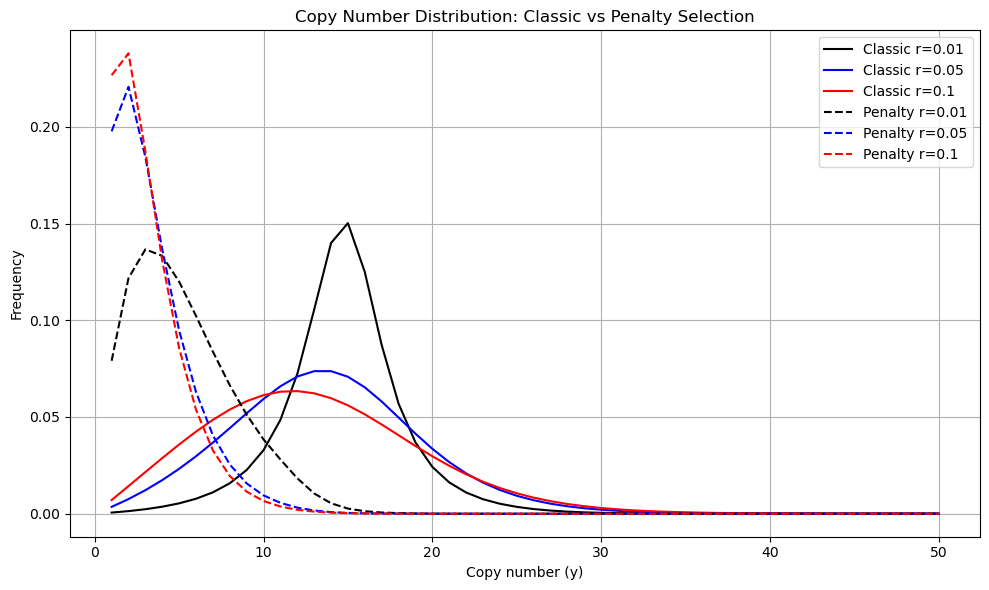

In [63]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Parameters
# -------------------------
sx = 0.02
sy = 0.005
eps = 0.05
recomb_rates = [0.01, 0.05, 0.1]
colors = ['black', 'blue', 'red']
k_vals = np.arange(1, 51)

# -------------------------
# Selection Functions
# -------------------------
def approx_sel_classic(y, sx=sx, sy=sy, eps=eps):
    s_tilde = eps * np.exp(-eps) * np.sqrt(sx * sy)
    y_opt = ((np.log(sx) - np.log(sy)) / (2 * eps)) + 1
    return np.maximum(0, 1 - s_tilde * (y - y_opt) ** 2)

def approx_sel_penalty(y, y1y2_diff, threshold=10, penalty_strength=0.01):
    penalty = np.where(y1y2_diff > threshold, 1 - penalty_strength * (y1y2_diff - threshold), 1.0)
    return np.clip(penalty, 0, 1.0)

# -------------------------
# Trapezoid Probability
# -------------------------
def trapez(k, y1, y2):
    result = np.zeros_like(k, dtype=float)
    result[(k <= y1) & (k <= y2)] = k[(k <= y1) & (k <= y2)]
    result[(k <= y1) & (k > y2)] = y2
    result[(k > y1) & (k <= y2)] = y1
    result[(k > y1) & (k > y2)] = y1 + y2 - k[(k > y1) & (k > y2)]
    result[(k < 1) | (k > (y1 + y2 - 1))] = 0
    return result / (y1 * y2)

# -------------------------
# Conditional Probabilities
# -------------------------
def conditional_prob(k, r, y1, y2):
    prob = np.zeros_like(k, dtype=float)
    if y1 == y2:
        prob[k == y1] = 1 - r
    else:
        prob[k == y1] += 0.5 * (1 - r)
        prob[k == y2] += 0.5 * (1 - r)
    prob += r * trapez(k, y1, y2)
    return prob

# -------------------------
# f_post: Update Distribution
# -------------------------
def f_post(k_vals, r, f_prior, selection_type="classic"):
    n = len(k_vals)
    f_new = np.zeros(n)

    for i, y1 in enumerate(k_vals):
        for j, y2 in enumerate(k_vals):
            weight = f_prior[i] * f_prior[j]

            if selection_type == "classic":
                weight *= approx_sel_classic(y1) * approx_sel_classic(y2)
            elif selection_type == "penalty":
                diff = abs(y1 - y2)
                weight *= approx_sel_penalty(k_vals, diff)

            f_new += weight * conditional_prob(k_vals, r, y1, y2)

    return f_new / np.sum(f_new)

# -------------------------
# Run Simulation
# -------------------------
def run_simulation(selection_type, init_mean=10, init_std=3):
    init = np.exp(-0.5 * ((k_vals - init_mean) / init_std) ** 2)
    init /= init.sum()
    current = init.copy()
    results = []

    for r, color in zip(recomb_rates, colors):
        prev = current.copy()
        for _ in range(2000):
            updated = f_post(k_vals, r, prev, selection_type=selection_type)
            if np.max(np.abs(updated - prev)) < 1e-6:
                break
            prev = updated
        results.append((k_vals, updated, r, color))
    return results

# -------------------------
# Plotting Function
# -------------------------
def plot_results(results, label_prefix):
    for k, dist, r, color in results:
        plt.plot(k, dist, label=f"{label_prefix} r={r}", color=color, linestyle='--' if label_prefix=='Penalty' else '-')

# -------------------------
# Execute Simulation and Plot
# -------------------------
classic_results = run_simulation("classic", init_mean=10, init_std=3)
penalty_results = run_simulation("penalty", init_mean=10, init_std=3)

plt.figure(figsize=(10,6))
plot_results(classic_results, "Classic")
plot_results(penalty_results, "Penalty")
plt.xlabel("Copy number (y)")
plt.ylabel("Frequency")
plt.title("Copy Number Distribution: Classic vs Penalty Selection")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

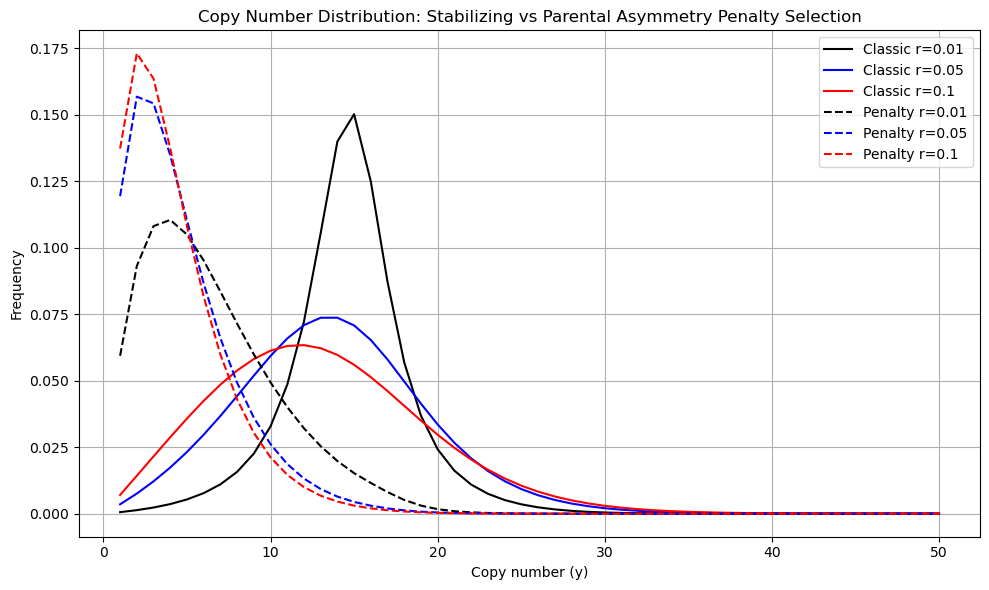

In [65]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Parameters
# -------------------------
sx = 0.02
sy = 0.005
eps = 0.05
recomb_rates = [0.01, 0.05, 0.1]
colors = ['black', 'blue', 'red']
k_vals = np.arange(1, 51)

# -------------------------
# Selection Functions
# -------------------------
def approx_sel_classic(y, sx=sx, sy=sy, eps=eps):
    s_tilde = eps * np.exp(-eps) * np.sqrt(sx * sy)
    y_opt = ((np.log(sx) - np.log(sy)) / (2 * eps)) + 1
    return np.maximum(0, 1 - s_tilde * (y - y_opt) ** 2)

def approx_sel_penalty(y, y1y2_diff, threshold=15, penalty_strength=0.01):
    penalty = np.where(y1y2_diff > threshold, 1 - penalty_strength * (y1y2_diff - threshold), 1.0)
    return np.clip(penalty, 0, 1.0)

# -------------------------
# Trapezoid Probability
# -------------------------
def trapez(k, y1, y2):
    result = np.zeros_like(k, dtype=float)
    result[(k <= y1) & (k <= y2)] = k[(k <= y1) & (k <= y2)]
    result[(k <= y1) & (k > y2)] = y2
    result[(k > y1) & (k <= y2)] = y1
    result[(k > y1) & (k > y2)] = y1 + y2 - k[(k > y1) & (k > y2)]
    result[(k < 1) | (k > (y1 + y2 - 1))] = 0
    return result / (y1 * y2)

# -------------------------
# Conditional Probabilities
# -------------------------
def conditional_prob(k, r, y1, y2):
    prob = np.zeros_like(k, dtype=float)
    if y1 == y2:
        prob[k == y1] = 1 - r
    else:
        prob[k == y1] += 0.5 * (1 - r)
        prob[k == y2] += 0.5 * (1 - r)
    prob += r * trapez(k, y1, y2)
    return prob

# -------------------------
# f_post: Update Distribution
# -------------------------
def f_post(k_vals, r, f_prior, selection_type="classic"):
    n = len(k_vals)
    f_new = np.zeros(n)

    for i, y1 in enumerate(k_vals):
        for j, y2 in enumerate(k_vals):
            weight = f_prior[i] * f_prior[j]

            if selection_type == "classic":
                weight *= approx_sel_classic(y1) * approx_sel_classic(y2)
            elif selection_type == "penalty":
                diff = abs(y1 - y2)
                weight *= approx_sel_penalty(k_vals, diff)

            f_new += weight * conditional_prob(k_vals, r, y1, y2)

    return f_new / np.sum(f_new)

# -------------------------
# Run Simulation
# -------------------------
def run_simulation(selection_type, init_mean=20, init_std=3):
    init = np.exp(-0.5 * ((k_vals - init_mean) / init_std) ** 2)
    init /= init.sum()
    current = init.copy()
    results = []

    for r, color in zip(recomb_rates, colors):
        prev = current.copy()
        for _ in range(2000):
            updated = f_post(k_vals, r, prev, selection_type=selection_type)
            if np.max(np.abs(updated - prev)) < 1e-6:
                break
            prev = updated
        results.append((k_vals, updated, r, color))
    return results

# -------------------------
# Plotting Function
# -------------------------
def plot_results(results, label_prefix):
    for k, dist, r, color in results:
        plt.plot(k, dist, label=f"{label_prefix} r={r}", color=color, linestyle='--' if label_prefix=='Penalty' else '-')

# -------------------------
# Execute Simulation and Plot
# -------------------------
classic_results = run_simulation("classic", init_mean=10, init_std=3)
penalty_results = run_simulation("penalty", init_mean=10, init_std=3)

plt.figure(figsize=(10,6))
plot_results(classic_results, "Classic")
plot_results(penalty_results, "Penalty")
plt.xlabel("Copy number (y)")
plt.ylabel("Frequency")
plt.title("Copy Number Distribution: Stabilizing vs Parental Asymmetry Penalty Selection")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

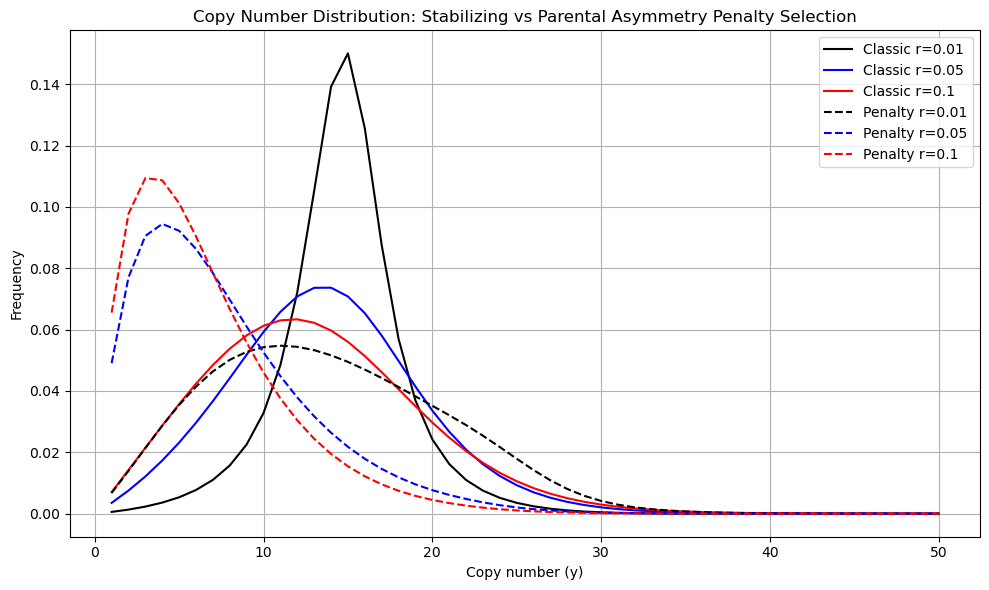

In [69]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Parameters
# -------------------------
sx = 0.02
sy = 0.005
eps = 0.05
recomb_rates = [0.01, 0.05, 0.1]
colors = ['black', 'blue', 'red']
k_vals = np.arange(1, 101)

# -------------------------
# Selection Functions
# -------------------------

# Otto-style stabilizing selection
def approx_sel_classic(y, sx=sx, sy=sy, eps=eps):
    s_tilde = eps * np.exp(-eps) * np.sqrt(sx * sy)
    y_opt = ((np.log(sx) - np.log(sy)) / (2 * eps)) + 1
    return np.maximum(0, 1 - s_tilde * (y - y_opt) ** 2)

# NEW: scalar penalty on mating pair fitness
def approx_sel_penalty_scalar(y1, y2, threshold=20, penalty_strength=0.01):
    diff = abs(y1 - y2)
    if diff <= threshold:
        return 1.0
    penalty = 1 - penalty_strength * (diff - threshold)
    return max(0.0, penalty)

# -------------------------
# Trapezoid Probability for recombination
# -------------------------
def trapez(k, y1, y2):
    result = np.zeros_like(k, dtype=float) #start with all zeros
    result[(k <= y1) & (k <= y2)] = k[(k <= y1) & (k <= y2)]
    result[(k <= y1) & (k > y2)] = y2
    result[(k > y1) & (k <= y2)] = y1
    result[(k > y1) & (k > y2)] = y1 + y2 - k[(k > y1) & (k > y2)]
    result[(k < 1) | (k > (y1 + y2 - 1))] = 0
    return result / (y1 * y2)

# -------------------------
# Conditional Probabilities with recombination
# -------------------------
def conditional_prob(k, r, y1, y2):
    prob = np.zeros_like(k, dtype=float)
    if y1 == y2:
        prob[k == y1] = 1 - r
    else:
        prob[k == y1] += 0.5 * (1 - r)
        prob[k == y2] += 0.5 * (1 - r)
    prob += r * trapez(k, y1, y2)
    return prob

# -------------------------
# Update Distribution f_post
# -------------------------
def f_post(k_vals, r, f_prior, selection_type="classic"):
    n = len(k_vals)
    f_new = np.zeros(n)

    for i, y1 in enumerate(k_vals):
        for j, y2 in enumerate(k_vals):
            weight = f_prior[i] * f_prior[j]

            if selection_type == "classic":
                weight *= approx_sel_classic(y1) * approx_sel_classic(y2)
            elif selection_type == "penalty":
                # NEW: pure mating-pair penalty (scalar)
                weight *= approx_sel_penalty_scalar(y1, y2)

            # Add contribution of this mating pair to all k
            f_new += weight * conditional_prob(k_vals, r, y1, y2)

    return f_new / np.sum(f_new)

# -------------------------
# Simulation Loop
# -------------------------
def run_simulation(selection_type, init_mean=20, init_std=5):
    init = np.exp(-0.5 * ((k_vals - init_mean) / init_std) ** 2)
    init /= init.sum()
    current = init.copy()
    results = []

    for r, color in zip(recomb_rates, colors):
        prev = current.copy()
        for _ in range(1000):
            updated = f_post(k_vals, r, prev, selection_type=selection_type)
            if np.max(np.abs(updated - prev)) < 1e-6:
                break
            prev = updated
        results.append((k_vals, updated, r, color))
    return results

# -------------------------
# Plotting
# -------------------------
def plot_results(results, label_prefix):
    for k, dist, r, color in results:
        plt.plot(k, dist, label=f"{label_prefix} r={r}",
                 color=color,
                 linestyle='--' if label_prefix=='Penalty' else '-')

# -------------------------
# Execute & Plot
# -------------------------
classic_results = run_simulation("classic", init_mean=20, init_std=5)
penalty_results = run_simulation("penalty", init_mean=20, init_std=5)

cutoff = 50

plt.figure(figsize=(10,6))

for k, dist, r, color in classic_results:
    mask = (k <= cutoff)
    plt.plot(k[mask], dist[mask], label=f"Classic r={r}", color=color)

for k, dist, r, color in penalty_results:
    mask = (k <= cutoff)
    plt.plot(k[mask], dist[mask], 
             label=f"Penalty r={r}",
             color=color,
             linestyle='--')

plt.xlabel("Copy number (y)")
plt.ylabel("Frequency")
plt.title("Copy Number Distribution: Stabilizing vs Parental Asymmetry Penalty Selection")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



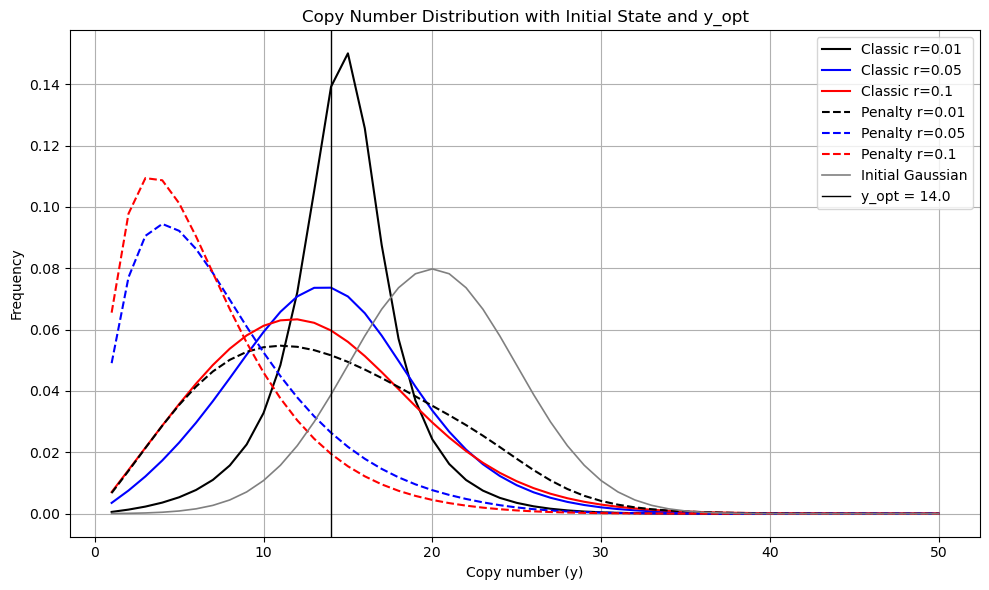

In [72]:
cutoff = 50

plt.figure(figsize=(10,6))

for k, dist, r, color in classic_results:
    mask = (k <= cutoff)
    plt.plot(k[mask], dist[mask], label=f"Classic r={r}", color=color)

for k, dist, r, color in penalty_results:
    mask = (k <= cutoff)
    plt.plot(k[mask], dist[mask], 
             label=f"Penalty r={r}",
             color=color,
             linestyle='--')

init_mean = 20
init_std = 5
init_raw = np.exp(-0.5 * ((k_vals - init_mean) / init_std) ** 2)
init_raw /= init_raw.sum()

mask = (k_vals <= cutoff)
plt.plot(k_vals[mask], init_raw[mask],
         color="grey",
         linewidth=1.2,
         label="Initial Gaussian")

plt.axvline(y_opt,
            color="black",
            linewidth=1,
            label=f"y_opt = {y_opt:.1f}")

# Labels etc.
plt.xlabel("Copy number (y)")
plt.ylabel("Frequency")
plt.title("Copy Number Distribution with Initial State and y_opt")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


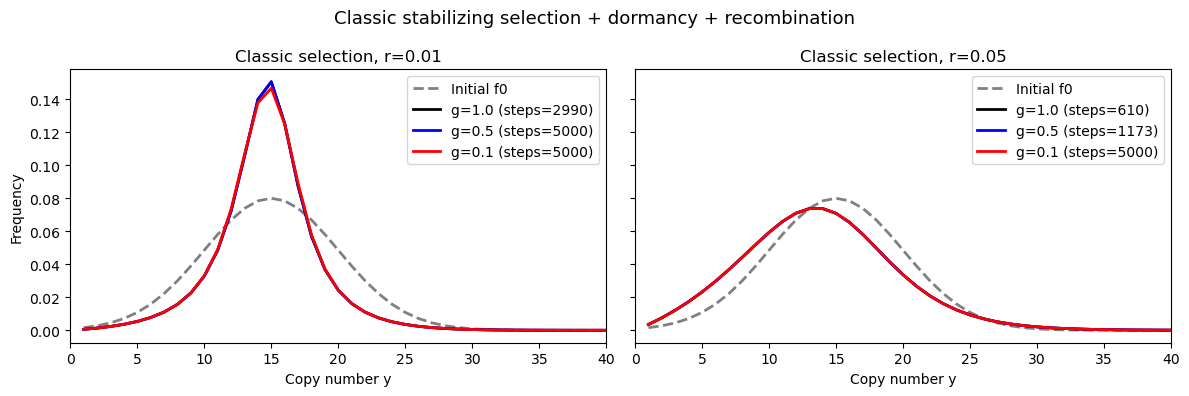

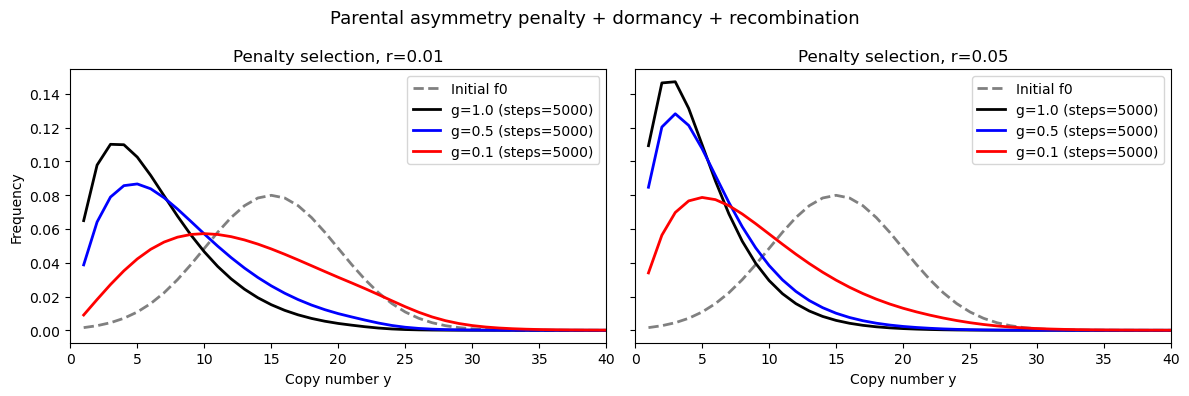

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- parameters for classic selection ----------
sx = 0.02
sy = 0.005
eps = 0.05

# ---------- trapezoid kernel for unequal recombination ----------
def trapez_tensor(n: int) -> np.ndarray:
    K  = np.arange(1, n + 1)[:, None, None]
    Y1 = np.arange(1, n + 1)[None, :, None]
    Y2 = np.arange(1, n + 1)[None, None, :]

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T  # shape (n, n, n)

# ---------- neutral dormancy / germination update ----------
def f_post_neutral_germination(f_prior, r, g, T):
    """Deterministic neutral model with germination rate g."""
    f_prior = f_prior / f_prior.sum()
    # recombination part: parents drawn i~f, j~f
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)
    # with prob 1-r, copy parental chromosome; with prob r, recombine
    f_new = (1 - r) * f_prior + r * recomb
    # dormancy mixing: g fraction replaced by new, (1-g) remain from previous generation
    f_post = g * f_new + (1 - g) * f_prior
    return f_post / f_post.sum()

def iterate_germination(f0, r, g, T, tol=1e-9, max_iter=1000):
    f = f0 / f0.sum()
    for i in range(max_iter):
        f_new = f_post_neutral_germination(f, r, g, T)
        if np.abs(f_new - f).sum() < tol:
            return f_new, i
        f = f_new
    return f, max_iter

# ---------- theoretical neutral stationary (only for g=1) ----------
def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    return p / p.sum()

# ---------- selection functions ----------
def approx_sel_classic(y, sx=sx, sy=sy, eps=eps):
    """Otto-style stabilizing selection: w(y) = max(0, 1 - s_tilde (y - y_opt)^2)."""
    s_tilde = eps * np.exp(-eps) * np.sqrt(sx * sy)
    y_opt = ((np.log(sx) - np.log(sy)) / (2 * eps)) + 1
    return np.maximum(0.0, 1.0 - s_tilde * (y - y_opt) ** 2)

def approx_sel_penalty_scalar(y1, y2, threshold=20, penalty_strength=0.01):
    """Pair-level penalty: if |y1 - y2| > threshold, fitness decreases linearly."""
    diff = abs(y1 - y2)
    if diff <= threshold:
        return 1.0
    penalty = 1.0 - penalty_strength * (diff - threshold)
    return max(0.0, penalty)

def pair_weights_with_selection(f_prior, selection_type, sx=sx, sy=sy, eps=eps):
    """
    Construct normalized pair weights:
    P_ij ∝ f_prior[i] * f_prior[j] * W(i,j),
    where W is pair fitness depending on selection_type.
    """
    f = f_prior / f_prior.sum()
    n = len(f)
    y_vals = np.arange(1, n + 1)

    if selection_type == "neutral":
        W = np.ones((n, n), dtype=float)
    elif selection_type == "classic":
        w = approx_sel_classic(y_vals, sx=sx, sy=sy, eps=eps)
        W = np.outer(w, w)  # W_ij = w_i * w_j
    elif selection_type == "penalty":
        W = np.zeros((n, n), dtype=float)
        for i in range(n):
            for j in range(n):
                W[i, j] = approx_sel_penalty_scalar(y_vals[i], y_vals[j])
    else:
        raise ValueError("Unknown selection_type")

    pair = f[:, None] * f[None, :] * W
    total = pair.sum()
    if total == 0.0:
        # if everything got zero fitness, fall back to neutral pairs
        pair = f[:, None] * f[None, :]
        total = pair.sum()
    return pair / total

# ---------- selection + recombination + dormancy update ----------
def f_post_selection_germination(f_prior, r, g, T, selection_type):
    """
    Deterministic model with selection (classic or penalty) + recombination + dormancy.
    - selection acts at pair level via pair_weights_with_selection
    - offspring from each pair:
        * with prob 1-r: no recombination → inherit y1 or y2 (0.5 each if y1!=y2)
        * with prob r: unequal recombination with kernel T
    - dormancy: fraction g replaced by new offspring; 1-g remain from previous f_prior
    """
    f_prior = f_prior / f_prior.sum()
    n = len(f_prior)
    y = np.arange(1, n + 1)

    # 1) construct selected pair distribution P_ij
    P = pair_weights_with_selection(f_prior, selection_type)

    # 2) non-recombination contribution
    nonrec = np.zeros(n, dtype=float)
    for i in range(n):
        for j in range(n):
            pij = P[i, j]
            if i == j:
                # offspring copy number = y_i with prob 1
                nonrec[i] += pij
            else:
                # offspring gets y_i or y_j with prob 0.5 each
                nonrec[i] += 0.5 * pij
                nonrec[j] += 0.5 * pij
    # nonrec is already normalized (sum ~ 1)

    # 3) recombination contribution using trapezoid kernel
    recomb = np.einsum('kij,ij->k', T, P, optimize=True)  # sum over i, j

    offspring = (1 - r) * nonrec + r * recomb

    # 4) dormancy mixing
    f_post = g * offspring + (1 - g) * f_prior
    return f_post / f_post.sum()

def iterate_selection_germination(f0, r, g, T, selection_type,
                                  tol=1e-9, max_iter=5000):
    f = f0 / f0.sum()
    for it in range(max_iter):
        f_new = f_post_selection_germination(f, r, g, T, selection_type)
        if np.abs(f_new - f).sum() < tol:
            return f_new, it
        f = f_new
    return f, max_iter

# ---------- run comparison ----------
if __name__ == "__main__":
    n = 80  # maximum copy number considered
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # initial distribution: gaussian around y=15
    f0 = np.exp(-((y - 15.0) ** 2) / (2 * 5.0 ** 2))
    f0 /= f0.sum()
    E0 = np.sum(y * f0)
    theory = stationary_theory_from_mean(E0, n)  # neutral, g=1 only

    recomb_rates = [0.01, 0.05]
    germ_rates   = [1.0, 0.5, 0.1]   # 1=no dormancy, 0.5=avg 2-gen dormancy, 0.1=strong
    colors       = ["black", "blue", "red"]

    # --------- Figure 2: Classic selection vs recombination & dormancy ----------
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, r in zip(axes, recomb_rates):
        ax.plot(y, f0, "gray", linestyle="--", lw=2, label="Initial f0")
        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_selection_germination(f0, r, g, T,
                                                        selection_type="classic")
            ax.plot(y, f_eq, lw=2, color=col,
                    label=f"g={g} (steps={steps})")
        ax.set_title(f"Classic selection, r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 40)
        ax.legend()
    axes[0].set_ylabel("Frequency")
    fig.suptitle("Classic stabilizing selection + dormancy + recombination", fontsize=13)
    plt.tight_layout()
    plt.show()

    # --------- Figure 3: Parental asymmetry penalty vs recombination & dormancy ----------
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, r in zip(axes, recomb_rates):
        ax.plot(y, f0, "gray", linestyle="--", lw=2, label="Initial f0")
        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_selection_germination(f0, r, g, T,
                                                        selection_type="penalty")
            ax.plot(y, f_eq, lw=2, color=col,
                    label=f"g={g} (steps={steps})")
        ax.set_title(f"Penalty selection, r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 40)
        ax.legend()
    axes[0].set_ylabel("Frequency")
    fig.suptitle("Parental asymmetry penalty + dormancy + recombination", fontsize=13)
    plt.tight_layout()
    plt.show()


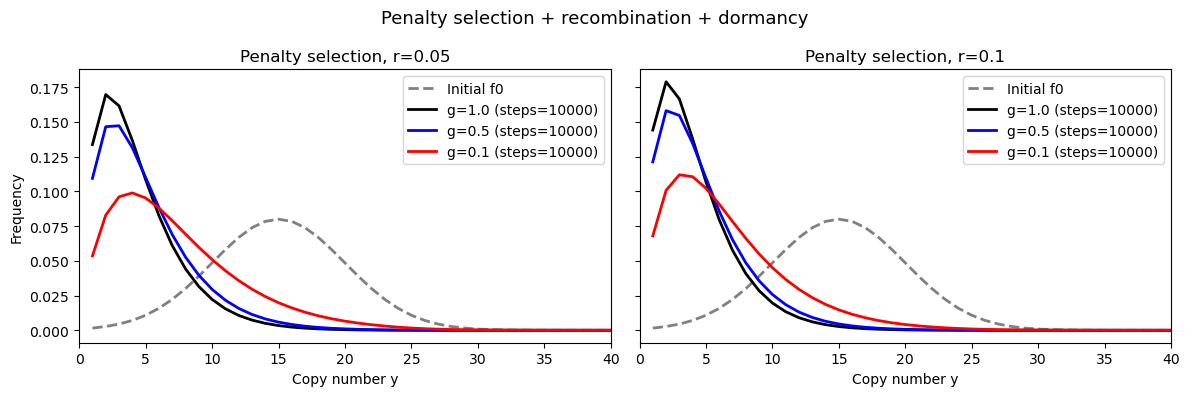

In [77]:

# ---------------- parameters ----------------
threshold = 20
penalty_strength = 0.01

# ---------------- trapezoid kernel ----------------
def trapez_tensor(n: int) -> np.ndarray:
    K  = np.arange(1, n + 1)[:, None, None]
    Y1 = np.arange(1, n + 1)[None, :, None]
    Y2 = np.arange(1, n + 1)[None, None, :]

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T

# ---------------- penalty selection ----------------
def approx_sel_penalty_scalar(y1, y2,
                              threshold=20,
                              penalty_strength=0.01):
    diff = abs(y1 - y2)
    if diff <= threshold:
        return 1.0
    penalty = 1.0 - penalty_strength * (diff - threshold)
    return max(0.0, penalty)

def pair_weights_penalty(f_prior,
                         threshold=20,
                         penalty_strength=0.01):
    f = f_prior / f_prior.sum()
    n = len(f)
    y_vals = np.arange(1, n + 1)

    W = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(n):
            W[i, j] = approx_sel_penalty_scalar(
                y_vals[i], y_vals[j],
                threshold=threshold,
                penalty_strength=penalty_strength
            )

    pair = f[:, None] * f[None, :] * W
    total = pair.sum()
    if total == 0:
        pair = f[:, None] * f[None, :]
        total = pair.sum()
    return pair / total

# ---------------- f_post with penalty + recombination + dormancy ----------------
def f_post_penalty_germination(f_prior, r, g, T,
                               threshold=20,
                               penalty_strength=0.01):
    f_prior = f_prior / f_prior.sum()
    n = len(f_prior)

    # 1. pair weights after penalty selection
    P = pair_weights_penalty(f_prior,
                             threshold=threshold,
                             penalty_strength=penalty_strength)

    # 2. non-recombination offspring
    nonrec = np.zeros(n, dtype=float)
    for i in range(n):
        for j in range(n):
            pij = P[i, j]
            if i == j:
                nonrec[i] += pij
            else:
                nonrec[i] += 0.5 * pij
                nonrec[j] += 0.5 * pij

    # 3. recombination offspring
    recomb = np.einsum('kij,ij->k', T, P, optimize=True)

    offspring = (1 - r) * nonrec + r * recomb

    # 4. dormancy mixing
    f_post = g * offspring + (1 - g) * f_prior
    return f_post / f_post.sum()

# ---------------- iterate until equilibrium ----------------
def iterate_penalty_germination(f0, r, g, T,
                                threshold=20,
                                penalty_strength=0.01,
                                tol=1e-9, max_iter=10000):
    f = f0 / f0.sum()
    for it in range(max_iter):
        f_new = f_post_penalty_germination(
            f, r, g, T,
            threshold=threshold,
            penalty_strength=penalty_strength
        )
        if np.abs(f_new - f).sum() < tol:
            return f_new, it
        f = f_new
    return f, max_iter

# ---------------- run and plot ----------------
if __name__ == "__main__":
    n = 80
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # initial distribution (Gaussian)
    f0 = np.exp(-((y - 15) ** 2) / (2 * 5 ** 2))
    f0 /= f0.sum()

    recomb_rates = [0.05, 0.1]
    germ_rates   = [1.0, 0.5, 0.1]  # dormancy strength
    colors       = ["black", "blue", "red"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    for ax, r in zip(axes, recomb_rates):
        ax.plot(y, f0, "gray", linestyle="--", lw=2,
                label="Initial f0")

        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_penalty_germination(
                f0, r, g, T,
                threshold=20,
                penalty_strength=0.01
            )
            ax.plot(y, f_eq, lw=2, color=col,
                    label=f"g={g} (steps={steps})")

        ax.set_title(f"Penalty selection, r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 40)
        ax.legend()

    axes[0].set_ylabel("Frequency")
    fig.suptitle("Penalty selection + recombination + dormancy", fontsize=13)
    plt.tight_layout()
    plt.show()


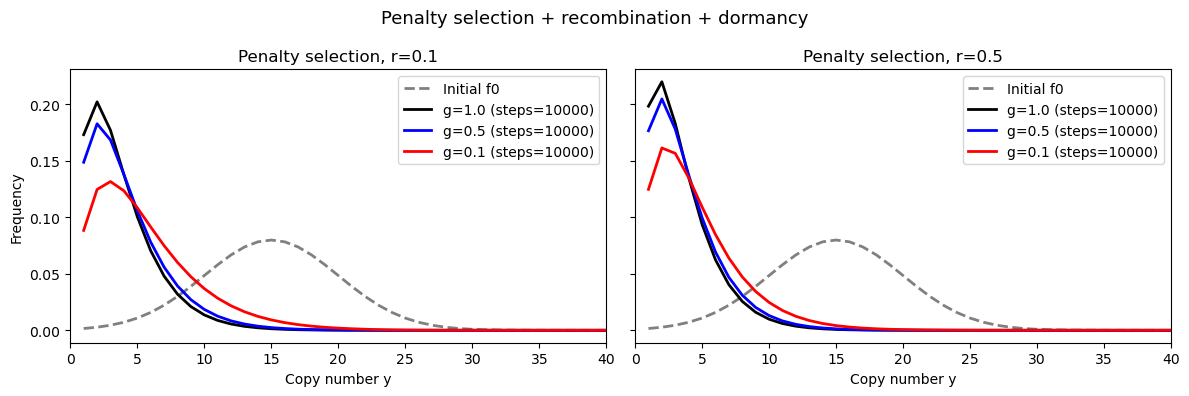

In [78]:
# ---------------- parameters ----------------
threshold = 20
penalty_strength = 0.01

# ---------------- trapezoid kernel ----------------
def trapez_tensor(n: int) -> np.ndarray:
    K  = np.arange(1, n + 1)[:, None, None]
    Y1 = np.arange(1, n + 1)[None, :, None]
    Y2 = np.arange(1, n + 1)[None, None, :]

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)
    valid = (K <= (ysum - 1))

    val = np.where(K <= ymin, K,
          np.where(K <= ymax, ymin,
          np.where(valid, ysum - K, 0.0)))
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T

# ---------------- penalty selection ----------------
def approx_sel_penalty_scalar(y1, y2,
                              threshold=20,
                              penalty_strength=0.01):
    diff = abs(y1 - y2)
    if diff <= threshold:
        return 1.0
    penalty = 1.0 - penalty_strength * (diff - threshold)
    return max(0.0, penalty)

def pair_weights_penalty(f_prior,
                         threshold=20,
                         penalty_strength=0.01):
    f = f_prior / f_prior.sum()
    n = len(f)
    y_vals = np.arange(1, n + 1)

    W = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(n):
            W[i, j] = approx_sel_penalty_scalar(
                y_vals[i], y_vals[j],
                threshold=threshold,
                penalty_strength=penalty_strength
            )

    pair = f[:, None] * f[None, :] * W
    total = pair.sum()
    if total == 0:
        pair = f[:, None] * f[None, :]
        total = pair.sum()
    return pair / total

# ---------------- f_post with penalty + recombination + dormancy ----------------
def f_post_penalty_germination(f_prior, r, g, T,
                               threshold=20,
                               penalty_strength=0.01):
    f_prior = f_prior / f_prior.sum()
    n = len(f_prior)

    # 1. pair weights after penalty selection
    P = pair_weights_penalty(f_prior,
                             threshold=threshold,
                             penalty_strength=penalty_strength)

    # 2. non-recombination offspring
    nonrec = np.zeros(n, dtype=float)
    for i in range(n):
        for j in range(n):
            pij = P[i, j]
            if i == j:
                nonrec[i] += pij
            else:
                nonrec[i] += 0.5 * pij
                nonrec[j] += 0.5 * pij

    # 3. recombination offspring
    recomb = np.einsum('kij,ij->k', T, P, optimize=True)

    offspring = (1 - r) * nonrec + r * recomb

    # 4. dormancy mixing
    f_post = g * offspring + (1 - g) * f_prior
    return f_post / f_post.sum()

# ---------------- iterate until equilibrium ----------------
def iterate_penalty_germination(f0, r, g, T,
                                threshold=20,
                                penalty_strength=0.01,
                                tol=1e-9, max_iter=10000):
    f = f0 / f0.sum()
    for it in range(max_iter):
        f_new = f_post_penalty_germination(
            f, r, g, T,
            threshold=threshold,
            penalty_strength=penalty_strength
        )
        if np.abs(f_new - f).sum() < tol:
            return f_new, it
        f = f_new
    return f, max_iter

# ---------------- run and plot ----------------
if __name__ == "__main__":
    n = 80
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # initial distribution (Gaussian)
    f0 = np.exp(-((y - 15) ** 2) / (2 * 5 ** 2))
    f0 /= f0.sum()

    recomb_rates = [0.1, 0.5]
    germ_rates   = [1.0, 0.5, 0.1]  # dormancy strength
    colors       = ["black", "blue", "red"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    for ax, r in zip(axes, recomb_rates):
        ax.plot(y, f0, "gray", linestyle="--", lw=2,
                label="Initial f0")

        for g, col in zip(germ_rates, colors):
            f_eq, steps = iterate_penalty_germination(
                f0, r, g, T,
                threshold=20,
                penalty_strength=0.05
            )
            ax.plot(y, f_eq, lw=2, color=col,
                    label=f"g={g} (steps={steps})")

        ax.set_title(f"Penalty selection, r={r}")
        ax.set_xlabel("Copy number y")
        ax.set_xlim(0, 40)
        ax.legend()

    axes[0].set_ylabel("Frequency")
    fig.suptitle("Penalty selection + recombination + dormancy", fontsize=13)
    plt.tight_layout()
    plt.show()